# Практична робота №14
## Параметричні критерії: t-критерії та порівняння дисперсій

**Виконав:** Панасюк Дмитро  
**Номер за списком:** 15  
**Варіант:** №5 — Дніпро  
**Регіон:** Схід  
**Довідкова норма вологості:** 70%  
**Рівень значущості:** α = 0,05

**Мета:** перевірити середню вологість міста відносно норми (`ttest_1samp`), порівняти дві незалежні вибірки після `levene()` (`ttest_ind`) і оцінити парні вимірювання вранці та ввечері (`ttest_rel`). Дані — навчальні, з методичних вказівок.

### Початкові дані та підготовка

Використовуємо місячні значення відносної вологості о 8:00 для міст із таблиці варіантів. Основна вибірка — 12 місяців Дніпра. Для порівнянь залучимо Львів (Захід) і Одесу (Південь), а для перевірки можливих кандидатів у Завданні 4 — решту міст.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

alpha = 0.05
norm_humidity = 70.0
months = ["Січ", "Лют", "Бер", "Кві", "Тра", "Чер", "Лип", "Сер", "Вер", "Жов", "Лис", "Гру"]

humidity_by_city = {
    "Київ":             [84, 82, 78, 70, 65, 63, 61, 63, 68, 75, 81, 85],
    "Львів":            [85, 83, 80, 73, 68, 65, 63, 65, 70, 77, 82, 86],
    "Одеса":            [82, 80, 78, 74, 71, 69, 67, 68, 72, 76, 80, 83],
    "Харків":           [83, 80, 75, 68, 62, 60, 58, 60, 66, 73, 79, 84],
    "Дніпро":           [82, 79, 74, 67, 61, 59, 57, 59, 65, 72, 78, 83],
    "Чернігів":        [85, 83, 79, 71, 66, 63, 61, 63, 69, 76, 82, 86],
    "Івано-Франківськ": [86, 84, 81, 75, 70, 67, 65, 67, 72, 78, 83, 87],
    "Полтава":          [84, 81, 76, 69, 63, 61, 59, 61, 67, 74, 80, 85],
    "Суми":             [85, 82, 77, 70, 64, 62, 60, 62, 68, 75, 81, 86],
    "Ужгород":          [84, 82, 79, 73, 68, 66, 64, 66, 71, 77, 82, 85],
}
regions = {
    "Київ": "Центр", "Львів": "Захід", "Одеса": "Південь", "Харків": "Схід",
    "Дніпро": "Схід", "Чернігів": "Центр", "Івано-Франківськ": "Захід",
    "Полтава": "Центр", "Суми": "Схід", "Ужгород": "Захід",
}

morning = np.array(humidity_by_city["Дніпро"], dtype=float)
initial_table = pd.DataFrame({"місяць": months, "вологість_8_00_%": morning})
display(initial_table)
print(f"n = {morning.size}; норма = {norm_humidity:.0f}%; середнє = {morning.mean():.4f}%")

,місяць,вологість_8_00_%
0,Січ,82.0
1,Лют,79.0
2,Бер,74.0
3,Кві,67.0
4,Тра,61.0
5,Чер,59.0
6,Лип,57.0
7,Сер,59.0
8,Вер,65.0
9,Жов,72.0


n = 12; норма = 70%; середнє = 69.6667%


## Завдання 1. Одновибірковий t-критерій проти норми

- **H₀:** генеральна середня вологість Дніпра дорівнює 70% (`μ = 70`).
- **H₁:** генеральна середня вологість Дніпра відрізняється від 70% (`μ ≠ 70`).
- Тип перевірки — **двобічний**, оскільки нас цікавить будь-яке відхилення від довідкової норми.

In [2]:
test_one = stats.ttest_1samp(morning, popmean=norm_humidity)
print(f"Середня вологість: {morning.mean():.4f}%")
print(f"Вибіркове std: {morning.std(ddof=1):.4f} в.п.")
print(f"t = {test_one.statistic:.6f}; df = {len(morning) - 1}; p-value = {test_one.pvalue:.6f}")
print("Рішення:", "відхиляємо H₀" if test_one.pvalue < alpha else "не відхиляємо H₀")

Середня вологість: 69.6667%
Вибіркове std: 9.5473 в.п.
t = -0.120945; df = 11; p-value = 0.905916
Рішення: не відхиляємо H₀


**Письмовий висновок:** середня ранкова вологість за 12 місяців у Дніпрі дорівнює **69.67%**, а довідкова норма — **70%**. Одновибірковий двобічний t-критерій показав `t = -0.1209`, `p = 0.9059 > 0.05`. Отже, **підстав відхилити H₀ немає**: ці навчальні дані не засвідчують статистично значущого відхилення середньої вологості від норми. Це не доводить, що середня точно дорівнює 70%.

## Завдання 2. Ручна перевірка t-статистики

Використовуємо формулу `t = (x̄ − μ₀) / (s / √n)`; `s` розраховуємо з `ddof=1`, як і належить для вибіркового стандартного відхилення.

In [3]:
n = len(morning)
x_bar = morning.mean()
s = morning.std(ddof=1)
se = s / np.sqrt(n)
t_manual = (x_bar - norm_humidity) / se

print(f"x̄ = {x_bar:.6f}; s = {s:.6f}; SE = {se:.6f}")
print(f"Ручна t = {t_manual:.10f}")
print(f"ttest_1samp t = {test_one.statistic:.10f}")
print(f"Збіг: {np.isclose(t_manual, test_one.statistic, rtol=0, atol=1e-12)}")
assert np.isclose(t_manual, test_one.statistic, rtol=0, atol=1e-12)

x̄ = 69.666667; s = 9.547330; SE = 2.756077
Ручна t = -0.1209448617
ttest_1samp t = -0.1209448617
Збіг: True


**Пояснення:** ручне значення збігається зі значенням `stats.ttest_1samp()` у межах числової точності. У тесті використовується статистика Стьюдента з `df = 11` ступенями вільності.

## Завдання 3. Незалежний двовибірковий t-критерій

Вибираємо **Львів** (регіон **Захід**), відмінний від регіону Дніпра (Схід).

- **H₀ для Лівена:** дисперсії обох генеральних сукупностей однакові.
- **H₁ для Лівена:** дисперсії відрізняються.
- **H₀ для t-критерію:** середні вологості Дніпра й Львова однакові.
- **H₁ для t-критерію:** середні вологості різні.

In [4]:
lviv = np.array(humidity_by_city["Львів"], dtype=float)
levene_lviv = stats.levene(morning, lviv)
equal_var_lviv = bool(levene_lviv.pvalue >= alpha)
ind_lviv = stats.ttest_ind(morning, lviv, equal_var=equal_var_lviv)

print(f"Дніпро: mean={morning.mean():.4f}%, std={morning.std(ddof=1):.4f}")
print(f"Львів: mean={lviv.mean():.4f}%, std={lviv.std(ddof=1):.4f}")
print(f"Критерій Лівена: F={levene_lviv.statistic:.6f}, p={levene_lviv.pvalue:.6f}")
print(f"equal_var={equal_var_lviv} -> {'стандартний t-критерій' if equal_var_lviv else 'критерій Велча'}")
print(f"Двовибірковий t={ind_lviv.statistic:.6f}, p={ind_lviv.pvalue:.6f}")
print("Рішення t-критерію:", "відхиляємо H₀" if ind_lviv.pvalue < alpha else "не відхиляємо H₀")

Дніпро: mean=69.6667%, std=9.5473
Львів: mean=74.7500%, std=8.4437
Критерій Лівена: F=0.376521, p=0.545764
equal_var=True -> стандартний t-критерій
Двовибірковий t=-1.381603, p=0.180964
Рішення t-критерію: не відхиляємо H₀


**Письмовий висновок:** для Львова критерій Лівена дає `p = 0.5458 > 0.05`, тож статистичних підстав стверджувати нерівність дисперсій немає. **За алгоритмом практичної** обираємо `equal_var=True`. Двовибірковий критерій показав `p = 0.1810 > 0.05`: статистично значущої різниці середньої ранкової вологості між Дніпром і Львовом не виявлено.

## Завдання 4. Протилежний висновок критерію Лівена

Шукаємо третє місто **не зі Сходу і не із Заходу** (тобто з регіону, відмінного від регіону Львова), для якого результат Лівена має бути протилежним до Завдання 3. Для прозорості перевіряємо доступні міста і вибираємо перше відповідне.

In [5]:
candidate_results = []
for city, raw_values in humidity_by_city.items():
    if regions[city] in {"Схід", "Захід"}:
        continue
    values = np.array(raw_values, dtype=float)
    lev = stats.levene(morning, values)
    is_opposite = (lev.pvalue < alpha) != (levene_lviv.pvalue < alpha)
    candidate_results.append({
        "місто": city,
        "регіон": regions[city],
        "std": round(values.std(ddof=1), 4),
        "p_Лівена": lev.pvalue,
        "протилежний_висновок": is_opposite,
    })
candidates = pd.DataFrame(candidate_results)
display(candidates)

matching = candidates[candidates["протилежний_висновок"]]
assert not matching.empty, "Не знайдено міста з протилежним висновком Лівена"
third_city = matching.iloc[0]["місто"]
third_values = np.array(humidity_by_city[third_city], dtype=float)
levene_third = stats.levene(morning, third_values)
equal_var_third = bool(levene_third.pvalue >= alpha)
ind_third = stats.ttest_ind(morning, third_values, equal_var=equal_var_third)

print(f"Обране місто: {third_city} ({regions[third_city]})")
print(f"Дніпро std={morning.std(ddof=1):.4f}; {third_city} std={third_values.std(ddof=1):.4f}")
print(f"Лівен: F={levene_third.statistic:.6f}; p={levene_third.pvalue:.6f}")
print(f"equal_var={equal_var_third} -> {'стандартний t-критерій' if equal_var_third else 'критерій Велча'}")
print(f"t={ind_third.statistic:.6f}; p={ind_third.pvalue:.6f}")
print("Рішення t-критерію:", "відхиляємо H₀" if ind_third.pvalue < alpha else "не відхиляємо H₀")
assert regions[third_city] != regions["Львів"]
assert (levene_third.pvalue < alpha) != (levene_lviv.pvalue < alpha)

,місто,регіон,std,p_Лівена,протилежний_висновок
0,Київ,Центр,8.9489,0.785035,False
1,Одеса,Південь,5.6246,0.015980,True
2,Чернігів,Центр,9.2769,0.915239,False
3,Полтава,Центр,9.5473,1.000000,False


Обране місто: Одеса (Південь)
Дніпро std=9.5473; Одеса std=5.6246
Лівен: F=6.813202; p=0.015980
equal_var=False -> критерій Велча
t=-1.667292; p=0.112939
Рішення t-критерію: не відхиляємо H₀


**Письмовий висновок:** знайдено **Одесу** (Південь). Для Дніпра й Одеси Лівен дає `p = 0.0160 < 0.05`: на відміну від Завдання 3, гіпотезу рівності дисперсій **відхиляємо**. Тому тепер потрібен **критерій Велча**, `equal_var=False`. Результат `p = 0.1129 > 0.05` не дає підстав стверджувати, що середні вологості Дніпра й Одеси статистично значуще відрізняються.

Порівняння стандартних відхилень узгоджується з цим: Дніпро — **9.55 в.п.**, Одеса — **5.62 в.п.**, тобто розкид в Одесі помітно менший. Для Львова він ближчий до Дніпра (8.44 проти 9.55 в.п.), хоча самі значення `std` не замінюють формального тесту.

### Наочне порівняння розкиду (допоміжний графік)

Boxplot допомагає візуально оцінити різницю між трьома вибірками, але сам по собі не вирішує, чи є вона статистично значущою.

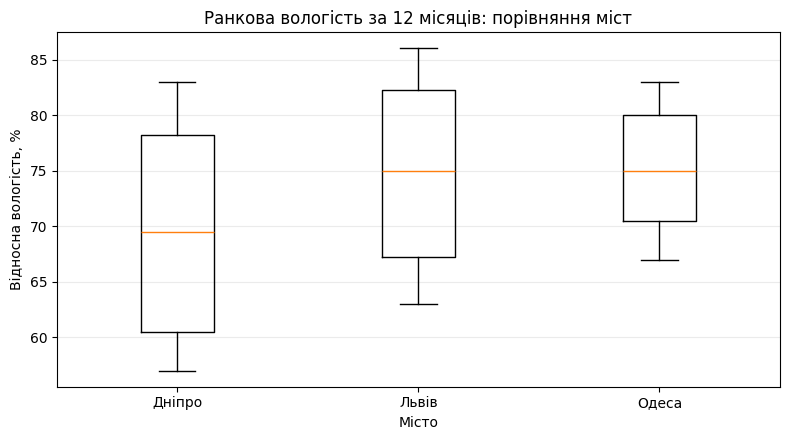

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot([morning, lviv, third_values], tick_labels=["Дніпро", "Львів", third_city])
ax.set_title("Ранкова вологість за 12 місяців: порівняння міст")
ax.set_xlabel("Місто")
ax.set_ylabel("Відносна вологість, %")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

## Завдання 5. Парний t-критерій: ранок проти вечора

Для кожного місяця від ранкового вимірювання віднімаємо відповідну добову амплітуду з умови. Вимірювання пов'язані **парами за місяцями**, тому застосовуємо `ttest_rel`, а не `ttest_ind`.

- **H₀:** середня різниця «ранок − вечір» дорівнює нулю.
- **H₁:** середня парна різниця не дорівнює нулю.

In [7]:
amplitude = np.array([3, 3, 4, 5, 6, 7, 7, 7, 6, 5, 4, 3], dtype=float)
evening = morning - amplitude
paired_difference = morning - evening
paired_test = stats.ttest_rel(morning, evening)

paired_table = pd.DataFrame({
    "місяць": months,
    "ранок_8_00_%": morning,
    "вечір_20_00_%": evening,
    "різниця_в_пп": paired_difference,
})
display(paired_table)
print(f"Ранок: mean={morning.mean():.4f}%")
print(f"Вечір: mean={evening.mean():.4f}%")
print(f"Середня парна різниця: {paired_difference.mean():.4f} в.п.")
print(f"ttest_rel: t={paired_test.statistic:.6f}, p={paired_test.pvalue:.10g}")
print("Рішення:", "відхиляємо H₀" if paired_test.pvalue < alpha else "не відхиляємо H₀")

,місяць,ранок_8_00_%,вечір_20_00_%,різниця_в_пп
0,Січ,82.0,79.0,3.0
1,Лют,79.0,76.0,3.0
2,Бер,74.0,70.0,4.0
3,Кві,67.0,62.0,5.0
4,Тра,61.0,55.0,6.0
5,Чер,59.0,52.0,7.0
6,Лип,57.0,50.0,7.0
7,Сер,59.0,52.0,7.0
8,Вер,65.0,59.0,6.0
9,Жов,72.0,67.0,5.0


Ранок: mean=69.6667%
Вечір: mean=64.6667%
Середня парна різниця: 5.0000 в.п.
ttest_rel: t=10.856203, p=3.234104031e-07
Рішення: відхиляємо H₀


**Письмовий висновок:** `t = 10.8562`, `p = 3.234e-07 < 0.05`; **H₀ відхиляємо**. У навчальних даних середня вологість о 8:00 в Дніпрі вища за вечірню о 20:00 на **5.00 відсоткового пункту**. Парний t-критерій порівнює не незалежні групи, а 12 різниць у рамках кожного місяця. Це прибирає спільний сезонний рівень конкретного місяця з кожної пари та зменшує зайву міжмісячну варіативність.

## Контрольні питання — письмові відповіді

**1. Чому для середнього однієї вибірки використовується t-, а не z-розподіл?**  
Справжнє стандартне відхилення генеральної сукупності `σ` невідоме; замість нього використовується вибіркове `s`. За невеликого розміру вибірки (12 місяців) оцінювання `σ` додає невизначеність, яку враховує розподіл Стьюдента з `n − 1 = 11` ступенями вільності. Використання звичайного z-критерію ігнорувало б цю додаткову невизначеність.

**2. Чому неправильний вибір `equal_var` здатний спотворити p-value?**  
Стандартний незалежний t-критерій (`equal_var=True`) об'єднує дві вибіркові дисперсії в одну оцінку та використовує певну формулу стандартної похибки і ступенів вільності. Якщо дисперсії справді різні, цей підхід може неправильно оцінити розподіл статистики й рівень помилки I роду, особливо за неоднакових розмірів вибірок. Welch (`equal_var=False`) не припускає рівності дисперсій. У цій роботі варіант вибирається за результатом Лівена, як вимагає методичка; водночас `p ≥ 0.05` у Лівена **не доводить** тотожність дисперсій.

**3. Чому парний критерій потужніший для даних «до/після»?**  
Ранок і вечір належать до одного й того самого місяця, тому значення корельовані через сезон. Віднімання вечірнього вимірювання від ранкового в межах кожної пари прибирає частину спільних міжмісячних коливань. Критерій перевіряє середню саме цих 12 різниць і часто має вищу потужність порівняно з незалежним тестом на пов'язаних спостереженнях.

**4. Чи узгоджується Лівен із видимими стандартними відхиленнями?**  
Так. Для Львова розкид ближчий до Дніпра (8.44 проти 9.55 в.п.), і Лівен не відхиляє рівність дисперсій (`p ≈ 0.5458`). Для Одеси `std ≈ 5.62` проти `9.55` в.п. у Дніпра; Лівен відхиляє рівність (`p ≈ 0.0160`). Водночас тест враховує розмір вибірки та статистичну невизначеність, тож за різницею `std` самою по собі не можна гарантовано передбачити його рішення.

## Підсумок

1. `ttest_1samp` не виявив статистично значущого відхилення середньої вологості Дніпра від норми 70%; ручна t-статистика збіглася з результатом SciPy.
2. Для Дніпра та Львова критерій Лівена не відхилив рівність дисперсій, тому за алгоритмом практичної застосовано стандартний `ttest_ind`.
3. Для Дніпра й Одеси критерій Лівена відхилив рівність дисперсій, тому застосовано Welch-варіант `ttest_ind`.
4. `ttest_rel` виявив статистично значущу різницю між ранковими та вечірніми значеннями вологості.

**Методична примітка:** ці 12 значень — послідовні місяці з виразною сезонністю, а не незалежна випадкова вибірка реальних щоденних вимірів. Тести застосовано за умовою навчальної практичної; їхні p-value не слід трактувати як строгі висновки про реальний клімат без перевірки припущень і дизайну спостережень.